# 6. R$ 500 mil à vista

Os notebooks 1 a 5 testam a pergunta com financiamento. Este parte de outro ponto, mais próximo de quem já tem o
dinheiro: **com R\$ 500 mil na mão, vale mais comprar um imóvel à vista e morar nele, ou aplicar em fundos
imobiliários que rendem 1% ao mês e pagar o aluguel com essa renda?**

O exemplo é Varginha (MG), com o preço e o aluguel da amostra de anúncios do notebook 5. A conta usa o mesmo
simulador dos outros notebooks, com entrada de 100%: quem compra não tem parcela, e quem aluga aplica todo o
dinheiro. É esta análise que a página do projeto conta.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from comprar_ou_alugar import cenarios, estilo
from comprar_ou_alugar.caminhos import TRATADOS
from comprar_ou_alugar.estilo import br, pct
from comprar_ou_alugar.financiamento import taxa_mensal
from comprar_ou_alugar.fontes import varginha
from comprar_ou_alugar.simulador import simular

estilo.aplicar()

DISPONIVEL = 500_000
INFLACAO = 0.045
UM_POR_CENTO = 0.01

anuncios = varginha.ler()
amostra = anuncios[varginha.plausivel(anuncios)]
mediana = amostra.groupby("negocio")["preco_m2"].median()

p = cenarios.compra_a_vista(DISPONIVEL, preco_m2=mediana["venda"], aluguel_m2=mediana["aluguel"])
print(f"Imóvel à vista: R$ {br(p.valor_imovel)} ({br(p.valor_imovel / mediana['venda'])} m²)")
print(f"Aluguel de um imóvel igual: R$ {br(p.aluguel_mensal)} por mês")
print(f"Aluguel de um ano ÷ preço: {pct(p.aluguel_mensal * 12 / p.valor_imovel, 1)}")

Imóvel à vista: R$ 476.190 (117 m²)
Aluguel de um imóvel igual: R$ 2.253 por mês
Aluguel de um ano ÷ preço: 5,7%


O aluguel de um ano dividido pelo preço dá 5,7%. O notebook 5 mostra 5,8% porque compõe os doze meses
(como o FipeZAP); o aluguel em reais é o mesmo.

## A conta do primeiro mês

Os R\$ 500 mil a 1% ao mês pagam R\$ 5.000, mais que o dobro do aluguel. Mas, se o preço da cota ficar parado, o
dinheiro aplicado perde a inflação, e parte da renda precisa ser reinvestida só para manter o patrimônio. Do outro
lado, quem compra não paga aluguel, mas paga a manutenção. Com o imóvel acompanhando a inflação, o patrimônio dos
dois continua valendo o mesmo, e o que sobra no mês é a diferença entre as duas escolhas.

In [2]:
renda = DISPONIVEL * UM_POR_CENTO
reposicao = DISPONIVEL * taxa_mensal(INFLACAO)
manutencao = p.valor_imovel * p.manutencao_aa / 12

conta = pd.DataFrame(
    {
        "quem aluga e investe": {
            "renda dos fundos": renda,
            "reposição da inflação (cota parada)": -reposicao,
            "aluguel": -p.aluguel_mensal,
            "manutenção": 0.0,
        },
        "quem compra à vista": {
            "renda dos fundos": 0.0,
            "reposição da inflação (cota parada)": 0.0,
            "aluguel": 0.0,
            "manutenção": -manutencao,
        },
    }
)
conta.loc["resultado do mês"] = conta.sum()
conta.map(lambda valor: f"R$ {br(valor)}")

,quem aluga e investe,quem compra à vista
renda dos fundos,R$ 5.000,R$ 0
reposição da inflação (cota parada),R$ -1.837,R$ 0
aluguel,R$ -2.253,R$ 0
manutenção,R$ 0,R$ -397
resultado do mês,R$ 910,R$ -397


## O 1% ao mês se sustenta?

O informe mensal da CVM diz quanto cada fundo distribuiu. A média do mercado (a mesma do notebook 3) fica abaixo de
1% ao mês em toda a série. O informe calcula o rendimento sobre o **valor patrimonial** da cota; na bolsa, quando
a cota está abaixo do valor patrimonial, o mesmo rendimento vira uma porcentagem maior. Um fundo que paga 1% sobre
o preço paga mais que a média ou tem a cota barata.

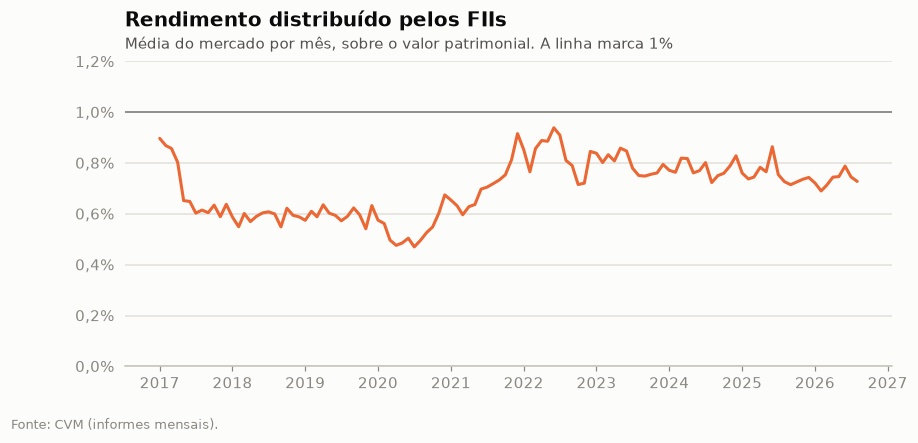

Média dos últimos 12 meses: 0,73% ao mês; maior mês da série: 0,94%
IFIX desde 2011, acima da inflação: 2,9% ao ano


In [3]:
mensal = pd.read_parquet(TRATADOS / "mensal.parquet").set_index("data")
rendimento = mensal["fii_dividend_yield_mes"].dropna()
media_do_mercado = rendimento.iloc[-12:].mean()

historico = mensal.loc["2011-01":, ["ifix_var_mes", "ipca_var_mes"]].dropna()
fii_real_aa = ((1 + historico["ifix_var_mes"]).prod() / (1 + historico["ipca_var_mes"]).prod()) ** (
    12 / len(historico)
) - 1

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(rendimento.index, rendimento, color=estilo.LARANJA, lw=2)
ax.axhline(UM_POR_CENTO, color=estilo.TINTA, lw=1, alpha=0.5)
ax.set_ylim(0, 0.012)
estilo.eixo_pct(ax.yaxis, casas=1)
estilo.titulo(
    ax, "Rendimento distribuído pelos FIIs", "Média do mercado por mês, sobre o valor patrimonial. A linha marca 1%"
)
estilo.fonte(fig, "Fonte: CVM (informes mensais).")
plt.show()

print(f"Média dos últimos 12 meses: {pct(media_do_mercado, 2)} ao mês; maior mês da série: {pct(rendimento.max(), 2)}")
print(f"IFIX desde 2011, acima da inflação: {pct(fii_real_aa, 1)} ao ano")

## Quem termina na frente

Três cenários para os fundos, com o imóvel e o aluguel acompanhando a inflação de 4,5% ao ano:

- **1% ao mês, cota parada**: a premissa da pergunta.
- **média dos FIIs hoje, cota parada**.
- **como desde 2011**: o rendimento médio de hoje e a variação da cota que, somada a ele, dá o retorno real que o
  IFIX entregou no período.

O número é o patrimônio de quem aluga menos o de quem compra, em milhares de reais de hoje.

In [4]:
PRAZOS = [5, 10, 20, 30]


def vantagem(rendimento_mes, cota_aa, anos, valorizacao_real_aa=0.0, parametros=p):
    cenario = cenarios.fundos_a_taxas_fixas(
        anos * 12,
        rendimento_mes=rendimento_mes,
        cota_aa=cota_aa,
        inflacao_aa=INFLACAO,
        valorizacao_real_aa=valorizacao_real_aa,
    )
    r = simular(parametros, cenario)
    return (r.patrimonio_inquilino[0, -1] - r.patrimonio_comprador[0, -1]) / r.deflator[0, -1]


cota_do_passado = (1 + fii_real_aa) * (1 + INFLACAO) / (1 + media_do_mercado) ** 12 - 1
fundos = {
    "1% ao mês, cota parada": (UM_POR_CENTO, 0.0),
    f"média dos FIIs hoje ({pct(media_do_mercado, 2)} ao mês), cota parada": (media_do_mercado, 0.0),
    f"como desde 2011 ({pct(fii_real_aa, 1)} ao ano acima da inflação)": (media_do_mercado, cota_do_passado),
}
quadro = pd.DataFrame(
    {f"{anos} anos": {nome: vantagem(rm, cota, anos) / 1000 for nome, (rm, cota) in fundos.items()} for anos in PRAZOS}
)
quadro.round(0)

,5 anos,10 anos,20 anos,30 anos
"1% ao mês, cota parada",150.0,293.0,803.0,1888.0
"média dos FIIs hoje (0,73% ao mês), cota parada",54.0,55.0,59.0,66.0
"como desde 2011 (2,9% ao ano acima da inflação)",14.0,-30.0,-141.0,-289.0


## Onde fica o empate

Com a cota parada, o rendimento mensal que empata as duas escolhas, para cada prazo e para três hipóteses de
valorização do imóvel acima da inflação:

In [5]:
def rendimento_do_empate(anos, valorizacao_real_aa=0.0, cota_aa=0.0, parametros=p):
    abaixo, acima = 0.0, 0.05
    for _ in range(40):
        meio = (abaixo + acima) / 2
        if vantagem(meio, cota_aa, anos, valorizacao_real_aa, parametros) > 0:
            acima = meio
        else:
            abaixo = meio
    return (abaixo + acima) / 2


empates = pd.DataFrame(
    {
        f"imóvel {pct(valorizacao, 0, True)} ao ano": {
            f"{anos} anos": rendimento_do_empate(anos, valorizacao) for anos in PRAZOS
        }
        for valorizacao in (-0.01, 0.0, 0.01)
    }
)
empates.map(lambda taxa: f"{pct(taxa, 2)} ao mês")

,imóvel −1% ao ano,imóvel 0% ao ano,imóvel +1% ao ano
5 anos,"0,48% ao mês","0,56% ao mês","0,65% ao mês"
10 anos,"0,57% ao mês","0,66% ao mês","0,74% ao mês"
20 anos,"0,62% ao mês","0,70% ao mês","0,78% ao mês"
30 anos,"0,63% ao mês","0,72% ao mês","0,80% ao mês"


O mapa abaixo mostra o resultado em 20 anos para cada combinação de rendimento e valorização, com a cota
parada. É o mesmo mapa do simulador da página.

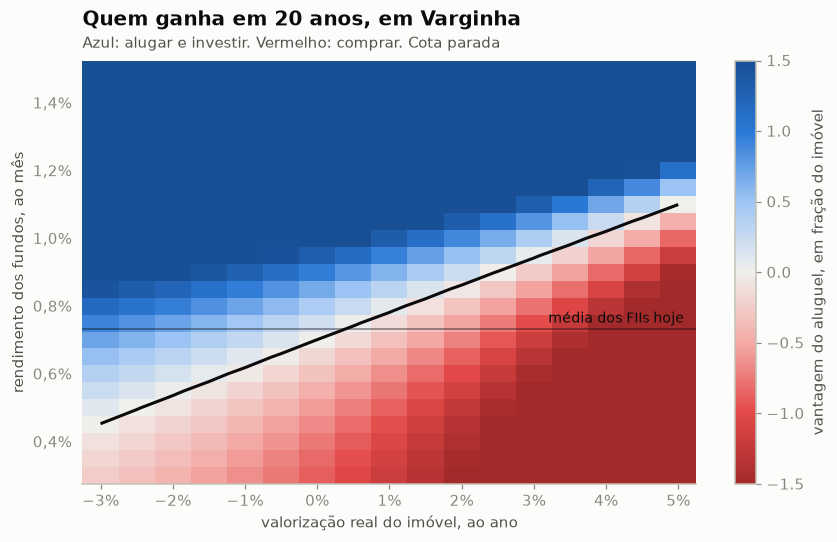

In [6]:
rendimentos = np.round(np.arange(0.003, 0.01501, 0.0005), 4)
valorizacoes = np.round(np.arange(-0.03, 0.05001, 0.005), 3)
grade = np.array([[vantagem(rm, 0.0, 20, val) / p.valor_imovel for val in valorizacoes] for rm in rendimentos])

fig, ax = plt.subplots(figsize=(9, 5))
mapa = ax.pcolormesh(valorizacoes, rendimentos, grade, cmap=estilo.DIVERGENTE, vmin=-1.5, vmax=1.5, shading="nearest")
ax.contour(valorizacoes, rendimentos, grade, levels=[0], colors=estilo.TINTA, linewidths=2)
ax.axhline(media_do_mercado, color=estilo.TINTA, lw=1, alpha=0.5)
ax.annotate(
    "média dos FIIs hoje",
    (valorizacoes[-1], media_do_mercado),
    xytext=(4, 4),
    textcoords="offset points",
    ha="right",
    fontsize=9,
)
estilo.eixo_pct(ax.xaxis)
estilo.eixo_pct(ax.yaxis, casas=1)
ax.set_xlabel("valorização real do imóvel, ao ano")
ax.set_ylabel("rendimento dos fundos, ao mês")
ax.grid(False)
fig.colorbar(mapa, ax=ax, label="vantagem do aluguel, em fração do imóvel")
estilo.titulo(ax, "Quem ganha em 20 anos, em Varginha", "Azul: alugar e investir. Vermelho: comprar. Cota parada")
plt.show()

## E se o aluguel de Varginha for outro?

A amostra de anúncios é pequena. O notebook 5 estima um intervalo de 90% de 4,6% a 10,3% ao ano para a
rentabilidade do aluguel. Quanto mais caro o aluguel em relação ao preço, mais rendimento a carteira precisa para
empatar:

In [7]:
sorteio = np.random.default_rng(0)
venda = amostra.loc[amostra["negocio"] == "venda", "preco_m2"].to_numpy()
aluguel = amostra.loc[amostra["negocio"] == "aluguel", "preco_m2"].to_numpy()
razao = np.median(sorteio.choice(aluguel, size=(10_000, len(aluguel))), axis=1) / np.median(
    sorteio.choice(venda, size=(10_000, len(venda))), axis=1
)

linhas = {}
for nome, aluguel_por_preco in {
    "extremo baixo": np.quantile(razao, 0.05),
    "estimativa central": mediana["aluguel"] / mediana["venda"],
    "extremo alto": np.quantile(razao, 0.95),
}.items():
    variante = cenarios.compra_a_vista(DISPONIVEL, preco_m2=1.0, aluguel_m2=aluguel_por_preco)
    linhas[nome] = {
        "aluguel mensal": f"R$ {br(variante.aluguel_mensal)}",
        "empate em 10 anos": f"{pct(rendimento_do_empate(10, parametros=variante), 2)} ao mês",
        "empate em 20 anos": f"{pct(rendimento_do_empate(20, parametros=variante), 2)} ao mês",
    }
pd.DataFrame(linhas).T

,aluguel mensal,empate em 10 anos,empate em 20 anos
extremo baixo,R$ 1.776,"0,56% ao mês","0,60% ao mês"
estimativa central,R$ 2.253,"0,66% ao mês","0,70% ao mês"
extremo alto,R$ 3.728,"0,96% ao mês","1,00% ao mês"


## Conclusões

Com os dados de outubro de 2026:

- **Com 1% ao mês e a cota parada, alugar e investir ganha com folga em todos os prazos**: R\$ 293 mil a mais em
  10 anos e R\$ 803 mil em 20, em dinheiro de hoje. Somando rendimento e cota, a carteira rende 7,8% ao ano acima
  da inflação.
- **Parte do 1% é inflação.** Dos R\$ 5.000 de renda, R\$ 1.837 só repõem o que a inflação tira dos R\$ 500 mil se
  a cota ficar parada. Mesmo assim sobram R\$ 910 depois do aluguel, contra R\$ 397 de manutenção de quem compra.
- **O empate fica perto do que os fundos pagam hoje.** Em 20 anos, com a cota parada e o imóvel acompanhando a
  inflação, as duas escolhas empatam com cerca de 0,70% ao mês. A média do mercado nos últimos 12 meses foi de 0,73%, sobre
  o valor patrimonial.
- **Se os fundos repetirem o que fizeram desde 2011, comprar passa à frente antes de dez anos**: R\$ 141 mil a
  mais em 20 anos.
- O resultado depende do aluguel de Varginha, que vem de uma amostra pequena. No extremo alto do intervalo
  (aluguel de R\$ 3.728), o empate em 20 anos pede 1,00% ao mês.